# CareFlow Hospital Operations —  Python Data Analysis

## Project overview
This beginner notebook analyzes a **synthetic** hospital event log. It uses Python and pandas to load data, inspect columns, check missing values and duplicates, clean essential fields, count activities, and calculate simple patient journey timings.

### Business questions
1. How many event records and unique patient cases are in the dataset?
2. Which hospital activities are recorded most often?
3. Are there missing values or exact duplicate rows?
4. What is the time between consecutive activities for each patient?
5. Which transitions have the longest average time?

## 1. Import libraries

`pandas` is used to read and analyze tabular data. `matplotlib` is used to create a basic chart.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Load the CSV dataset

In [2]:
CSV_PATH = Path("careflow_raw_event_log.csv")

if not CSV_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {CSV_PATH.resolve()}. "
        "Put careflow_raw_event_log.csv beside this notebook or update CSV_PATH."
    )

df_raw = pd.read_csv(CSV_PATH)
df = df_raw.copy()

print("Dataset loaded successfully.")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")
display(df.head())


Dataset loaded successfully.
Rows: 6,443
Columns: 9


,Case_ID,Activity_Name,Timestamp,Patient_Age,Gender,Department,Doctor_ID,Pathway_Type,Event_Reason
0,P0001,registration,2026-09-03 16:21:00,70,Male,Emergency,D02,Normal,NaN
1,P0001,Triage,2026-09-03 16:29:00,70,Male,Emergency,D02,Normal,NaN
2,P0001,Doctor,2026-09-03 16:57:00,70,Male,Emergency,D02,Normal,NaN
3,P0001,X-RAY,2026-09-03 17:16:00,70,Male,Emergency,D02,Normal,NaN
4,P0001,Treatment,2026-09-03 18:07:00,70,Male,Emergency,D02,Normal,NaN


## 3. Inspect columns and data types

This section shows the column names, data types, and a general summary. The notebook then maps common column-name variations to the standard names it uses.


In [3]:
print("Original column names:")
print(df.columns.tolist())

# Standardize spaces and common alternatives.
df.columns = [str(col).strip().replace(" ", "_") for col in df.columns]
rename_map = {
    "case_id": "Case_ID",
    "CaseID": "Case_ID",
    "activity_name": "Activity_Name",
    "Activity": "Activity_Name",
    "timestamp": "Timestamp",
    "DateTime": "Timestamp",
}
df = df.rename(columns={old: new for old, new in rename_map.items() if old in df.columns})

print("\nStandardized column names:")
print(df.columns.tolist())
df.info()


Original column names:
['Case_ID', 'Activity_Name', 'Timestamp', 'Patient_Age', 'Gender', 'Department', 'Doctor_ID', 'Pathway_Type', 'Event_Reason']

Standardized column names:
['Case_ID', 'Activity_Name', 'Timestamp', 'Patient_Age', 'Gender', 'Department', 'Doctor_ID', 'Pathway_Type', 'Event_Reason']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6443 entries, 0 to 6442
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Case_ID        6443 non-null   object
 1   Activity_Name  6443 non-null   object
 2   Timestamp      6443 non-null   object
 3   Patient_Age    6443 non-null   int64 
 4   Gender         6443 non-null   object
 5   Department     6443 non-null   object
 6   Doctor_ID      6443 non-null   object
 7   Pathway_Type   6443 non-null   object
 8   Event_Reason   436 non-null    object
dtypes: int64(1), object(8)
memory usage: 453.2+ KB


## 4. Validate required columns


In [4]:
required_columns = ["Case_ID", "Activity_Name", "Timestamp"]
missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(
        f"Required columns not found: {missing_columns}. "
        f"Available columns: {df.columns.tolist()}"
    )

print("All required columns are present.")


All required columns are present.


## 5. Check missing values and exact duplicates

A missing case ID, activity, or timestamp prevents reliable transition analysis. We first measure the issues before cleaning.


In [5]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": (df.isna().mean() * 100).round(2)
})
display(missing_summary)

duplicate_rows = int(df.duplicated().sum())
print(f"Exact duplicate rows: {duplicate_rows}")


,Missing_Count,Missing_Percent
Case_ID,0,0.00
Activity_Name,0,0.00
Timestamp,0,0.00
Patient_Age,0,0.00
Gender,0,0.00
Department,0,0.00
Doctor_ID,0,0.00
Pathway_Type,0,0.00
Event_Reason,6007,93.23


Exact duplicate rows: 8


## 6. Clean essential fields

Cleaning steps:
- Trim extra spaces from text fields.
- Convert timestamps to datetime.
- Remove rows missing a required case ID, activity, or valid timestamp.
- Remove exact duplicate rows.
- Sort records by patient and timestamp.


In [6]:
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype("string").str.strip()

df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")

rows_before = len(df)
df = df.dropna(subset=["Case_ID", "Activity_Name", "Timestamp"])
rows_after_required = len(df)

df = df.drop_duplicates()
rows_after_dedup = len(df)

df["Case_ID"] = df["Case_ID"].astype(str)
df["Activity_Name"] = df["Activity_Name"].astype(str)
df = df.sort_values(["Case_ID", "Timestamp"]).reset_index(drop=True)

print(f"Rows before cleaning: {rows_before:,}")
print(f"Rows after removing missing required fields/invalid timestamps: {rows_after_required:,}")
print(f"Rows after removing exact duplicates: {rows_after_dedup:,}")
print(f"Rows removed during cleaning: {rows_before - rows_after_dedup:,}")
display(df.head(10))


Rows before cleaning: 6,443
Rows after removing missing required fields/invalid timestamps: 6,443
Rows after removing exact duplicates: 6,435
Rows removed during cleaning: 8


,Case_ID,Activity_Name,Timestamp,Patient_Age,Gender,Department,Doctor_ID,Pathway_Type,Event_Reason
0,P0001,registration,2026-09-03 16:21:00,70,Male,Emergency,D02,Normal,<NA>
1,P0001,Triage,2026-09-03 16:29:00,70,Male,Emergency,D02,Normal,<NA>
2,P0001,Doctor,2026-09-03 16:57:00,70,Male,Emergency,D02,Normal,<NA>
3,P0001,X-RAY,2026-09-03 17:16:00,70,Male,Emergency,D02,Normal,<NA>
4,P0001,Treatment,2026-09-03 18:07:00,70,Male,Emergency,D02,Normal,<NA>
5,P0001,Discharge,2026-09-03 18:29:00,70,Male,Emergency,D02,Normal,<NA>
6,P0002,registration,2026-09-21 22:14:00,53,Female,Emergency,D15,Normal,<NA>
7,P0002,Triage,2026-09-21 22:27:00,53,Female,Emergency,D15,Normal,<NA>
8,P0002,Doctor,2026-09-21 22:39:00,53,Female,Emergency,D15,Normal,<NA>
9,P0002,X-RAY,2026-09-21 22:51:00,53,Female,Emergency,D15,Normal,<NA>


## 7. Calculate basic KPIs

These summary measures describe the cleaned event log.


In [7]:
total_events = len(df)
total_patients = df["Case_ID"].nunique()
unique_activities = df["Activity_Name"].nunique()
avg_events_per_patient = df.groupby("Case_ID").size().mean() if total_patients else 0

kpi_summary = pd.DataFrame({
    "Metric": [
        "Total cleaned event records",
        "Unique patient cases",
        "Unique activity types",
        "Average events per patient",
        "First timestamp",
        "Last timestamp",
    ],
    "Value": [
        total_events,
        total_patients,
        unique_activities,
        round(avg_events_per_patient, 2),
        df["Timestamp"].min(),
        df["Timestamp"].max(),
    ]
})
display(kpi_summary)


,Metric,Value
0,Total cleaned event records,6435
1,Unique patient cases,1000
2,Unique activity types,6
3,Average events per patient,6.44
4,First timestamp,2026-09-01 01:04:00
5,Last timestamp,2026-10-01 01:09:00


## 8. Count hospital activities

This answers: **Which activities are recorded most often?** Counts represent events, not necessarily unique patients.


,Activity_Name,Event_Count
0,Doctor,1240
1,Triage,1195
2,registration,1000
3,X-RAY,1000
4,Treatment,1000
5,Discharge,1000


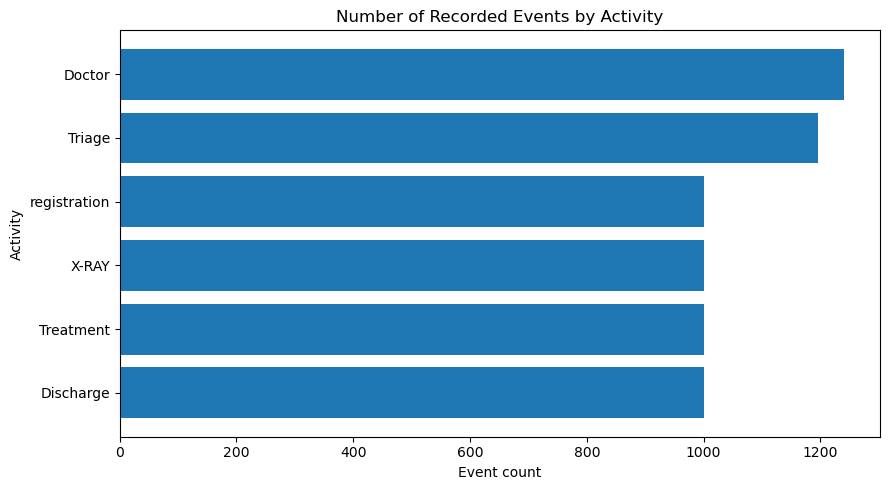

In [8]:
activity_counts = (
    df["Activity_Name"].value_counts()
    .rename_axis("Activity_Name")
    .reset_index(name="Event_Count")
)
display(activity_counts)

if not activity_counts.empty:
    plt.figure(figsize=(9, 5))
    plt.barh(activity_counts["Activity_Name"], activity_counts["Event_Count"])
    plt.title("Number of Recorded Events by Activity")
    plt.xlabel("Event count")
    plt.ylabel("Activity")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()


## 9. Calculate time between consecutive activities

For each patient, the next recorded activity is compared with the current event. The elapsed minutes are calculated as `next timestamp - current timestamp`.

This elapsed time is not automatically the same as a true waiting time; it can include planned care or gaps in event recording.


In [9]:
df["Next_Activity"] = df.groupby("Case_ID")["Activity_Name"].shift(-1)
df["Next_Timestamp"] = df.groupby("Case_ID")["Timestamp"].shift(-1)
df["Transition_Minutes"] = (
    (df["Next_Timestamp"] - df["Timestamp"]).dt.total_seconds() / 60
)

transitions = df.dropna(subset=["Next_Activity", "Next_Timestamp"]).copy()
negative_transition_count = int((transitions["Transition_Minutes"] < 0).sum())
valid_transitions = transitions[transitions["Transition_Minutes"] >= 0].copy()

print("Consecutive transitions:", len(transitions))
print("Negative durations to investigate:", negative_transition_count)

transition_summary = (
    valid_transitions.groupby(["Activity_Name", "Next_Activity"], as_index=False)
    .agg(
        Transition_Count=("Transition_Minutes", "size"),
        Average_Minutes=("Transition_Minutes", "mean"),
        Median_Minutes=("Transition_Minutes", "median")
    )
    .sort_values("Average_Minutes", ascending=False)
)
transition_summary[["Average_Minutes", "Median_Minutes"]] = (
    transition_summary[["Average_Minutes", "Median_Minutes"]].round(2)
)
display(transition_summary.head(10))


Consecutive transitions: 5435
Negative durations to investigate: 0


,Activity_Name,Next_Activity,Transition_Count,Average_Minutes,Median_Minutes
1,Doctor,Treatment,195,40.87,41.0
5,X-RAY,Treatment,805,39.71,40.0
6,X-RAY,Triage,195,25.35,25.0
4,Triage,Doctor,1195,22.38,22.0
2,Doctor,X-RAY,1000,20.02,20.0
3,Treatment,Discharge,1000,19.83,20.0
7,registration,Triage,1000,14.02,14.0
0,Doctor,Doctor,45,12.69,13.0


## 10. Check repeated activities (simple loopback indicator)

A repeated activity is an activity that appears again later in the same patient's recorded journey. Some repeats may be appropriate, so this is a review indicator rather than proof of inefficiency.


In [10]:
def flag_repeated_activities(group):
    seen = set()
    flags = []
    for activity in group["Activity_Name"]:
        flags.append(activity in seen)
        seen.add(activity)
    return pd.Series(flags, index=group.index)

df["Repeated_Activity_Flag"] = (
    df.groupby("Case_ID", group_keys=False)
      .apply(lambda group: flag_repeated_activities(group), include_groups=False)
      .reindex(df.index)
      .fillna(False)
      .astype(bool)
)

patients_with_repeats = int(df.groupby("Case_ID")["Repeated_Activity_Flag"].any().sum())
repeat_event_count = int(df["Repeated_Activity_Flag"].sum())
repeat_patient_percent = round(patients_with_repeats / total_patients * 100, 2) if total_patients else 0

print(f"Patients with a repeated activity: {patients_with_repeats:,}")
print(f"Percent of patients with a repeated activity: {repeat_patient_percent}%")
print(f"Repeated activity events: {repeat_event_count:,}")
display(df[df["Repeated_Activity_Flag"]].head(10))


Patients with a repeated activity: 240
Percent of patients with a repeated activity: 24.0%
Repeated activity events: 435


,Case_ID,Activity_Name,Timestamp,Patient_Age,Gender,Department,Doctor_ID,Pathway_Type,Event_Reason,Next_Activity,Next_Timestamp,Transition_Minutes,Repeated_Activity_Flag
16,P0003,Triage,2026-09-26 06:06:00,48,Male,Trauma,D12,XRay_Loop,Clinical re-check after X-Ray,Doctor,2026-09-26 06:28:00,22.0,True
17,P0003,Doctor,2026-09-26 06:28:00,48,Male,Trauma,D12,XRay_Loop,Clinical re-check,Treatment,2026-09-26 06:53:00,25.0,True
30,P0005,Triage,2026-09-26 19:17:00,74,Female,Emergency,D11,Paperwork_Loop,Missing paperwork/form,Doctor,2026-09-26 19:32:00,15.0,True
31,P0005,Doctor,2026-09-26 19:32:00,74,Female,Emergency,D11,Paperwork_Loop,Paperwork completed,Treatment,2026-09-26 20:18:00,46.0,True
44,P0007,Triage,2026-09-16 00:03:00,20,Male,Emergency,D14,Paperwork_Loop,Missing paperwork/form,Doctor,2026-09-16 00:25:00,22.0,True
45,P0007,Doctor,2026-09-16 00:25:00,20,Male,Emergency,D14,Paperwork_Loop,Paperwork completed,Treatment,2026-09-16 01:23:00,58.0,True
64,P0010,Triage,2026-09-21 03:51:00,28,Female,Emergency,D13,XRay_Loop,Clinical re-check after X-Ray,Doctor,2026-09-21 04:12:00,21.0,True
65,P0010,Doctor,2026-09-21 04:12:00,28,Female,Emergency,D13,XRay_Loop,Clinical re-check,Treatment,2026-09-21 05:07:00,55.0,True
144,P0023,Triage,2026-09-11 05:38:00,83,Female,Emergency,D07,Paperwork_Loop,Missing paperwork/form,Doctor,2026-09-11 05:52:00,14.0,True
145,P0023,Doctor,2026-09-11 05:52:00,83,Female,Emergency,D07,Paperwork_Loop,Paperwork completed,Treatment,2026-09-11 06:40:00,48.0,True


## 11. Business insights — calculated from this dataset


In [11]:
print("CAREFLOW BUSINESS INSIGHTS")
print("=" * 32)
print(
    f"The cleaned dataset contains {total_patients:,} unique patient cases and "
    f"{total_events:,} event records across {unique_activities} activity types."
)
print(
    f"During cleaning, {rows_before - rows_after_dedup:,} rows were removed because "
    "of missing/invalid required fields or exact duplication."
)

if not activity_counts.empty:
    most_common_activity = activity_counts.iloc[0]["Activity_Name"]
    most_common_count = int(activity_counts.iloc[0]["Event_Count"])
    print(
        f"The most frequently recorded activity is {most_common_activity}, "
        f"with {most_common_count:,} recorded events."
    )

if not transition_summary.empty:
    slowest = transition_summary.iloc[0]
    print(
        f"The highest average elapsed time among the observed transitions is "
        f"{slowest['Activity_Name']} → {slowest['Next_Activity']}: "
        f"{slowest['Average_Minutes']} minutes on average "
        f"(median {slowest['Median_Minutes']} minutes, "
        f"{int(slowest['Transition_Count'])} observations)."
    )
else:
    print("There are not enough valid consecutive events to summarize transition times.")

print(
    f"{patients_with_repeats:,} patients ({repeat_patient_percent}%) had at least one "
    "activity that repeated later in their recorded journey."
)
print(
    "\nRecommended follow-up: review the longest frequent transitions and repeated "
    "journeys with operational context before recommending process changes."
)
print(
    "\nLimitation: the data is synthetic. These findings do not describe a real "
    "hospital and do not prove that any process is unsafe or inefficient."
)


CAREFLOW BUSINESS INSIGHTS
The cleaned dataset contains 1,000 unique patient cases and 6,435 event records across 6 activity types.
During cleaning, 8 rows were removed because of missing/invalid required fields or exact duplication.
The most frequently recorded activity is Doctor, with 1,240 recorded events.
The highest average elapsed time among the observed transitions is Doctor → Treatment: 40.87 minutes on average (median 41.0 minutes, 195 observations).
240 patients (24.0%) had at least one activity that repeated later in their recorded journey.

Recommended follow-up: review the longest frequent transitions and repeated journeys with operational context before recommending process changes.

Limitation: the data is synthetic. These findings do not describe a real hospital and do not prove that any process is unsafe or inefficient.


## 12. Recommendations, risks, and how to measure improvement

### Recommendations
1. Review the longest average transitions first, using both average and median time.
2. Inspect repeated journeys to separate expected repeat activities from avoidable rework.
3. Confirm timestamps and activity definitions with the people who understand the process.
4. Create a baseline before making a change.
5. After a change, compare similar periods and patient groups.

### Risks and limitations
- Synthetic data may not reflect real hospital operations.
- Elapsed time between events may include planned treatment time or recording gaps.
- Repeated activities are not automatically mistakes.
- Small transition counts may produce unstable averages.

### Measurement plan
Track average and median transition time, transition count, and repeated-activity percentage before and after any process change. Also consider quality, safety, workload, and patient experience. Do not claim a percentage improvement unless it is calculated from valid comparable data.


## 13. Export results for Excel or Power BI

The files will be saved in an `outputs` folder in the notebook's current working directory.


In [12]:
from pathlib import Path

output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

exports = {
    "careflow_cleaned_event_log.csv": df,
    "careflow_kpi_summary.csv": kpi_summary,
    "careflow_activity_counts.csv": activity_counts,
    "careflow_transition_summary.csv": transition_summary,
    "careflow_repeated_activity_events.csv": df[df["Repeated_Activity_Flag"]]
}

for filename, table in exports.items():
    output_path = output_dir / filename
    table.to_csv(output_path, index=False)
    print(f"Saved: {output_path.resolve()}")

print("Export complete.")


Saved: C:\Users\hp\outputs\careflow_cleaned_event_log.csv
Saved: C:\Users\hp\outputs\careflow_kpi_summary.csv
Saved: C:\Users\hp\outputs\careflow_activity_counts.csv
Saved: C:\Users\hp\outputs\careflow_transition_summary.csv
Saved: C:\Users\hp\outputs\careflow_repeated_activity_events.csv
Export complete.


# 14. Final Conclusion

## 1. Dataset Overview
The CareFlow dataset contains **1,000 unique patient cases and 6,435 event records**, covering 6 different activity types. The dataset was analyzed using Python and pandas to understand hospital activity patterns, transition times, and repeated activities.

## 2. Data Quality and Cleaning
During data cleaning, **8 rows were removed** because of missing or invalid required fields or exact duplication. Cleaning helped prepare the dataset for further analysis.

## 3. Activity Analysis
**Doctor** was the most frequently recorded activity, with **1,240 recorded events**. This indicates that Doctor-related events appear most often in the dataset. However, a high event count alone does not prove that this stage is inefficient.

## 4. Waiting-Time and Transition Analysis
The transition from **Doctor to Treatment** had the highest average elapsed time among the observed transitions, at **40.87 minutes**. Its median elapsed time was **41 minutes**, based on **195 observations**. This transition should be investigated further to understand whether the elapsed time represents operational waiting, planned care, or gaps in event recording.

## 5. Repeated Activities
A total of **240 patients, representing 24% of all patient cases**, had at least one activity that repeated later in their recorded journey. These repeated activities may indicate process loops or rework, but they may also represent appropriate clinical steps. Further review is required before drawing conclusions.

## 6. Business Recommendations
- Review the Doctor-to-Treatment transition to understand the reasons for its relatively high elapsed time.
- Examine repeated patient journeys to distinguish expected repeat activities from avoidable process loops.
- Validate timestamps and activity definitions before making operational decisions.
- Establish baseline KPIs before introducing process changes.
- Compare average and median transition times and repeated-activity rates after any changes.

## 7. Limitations
The dataset contains synthetic practice records and does not represent real hospital performance. The time between two recorded activities is not necessarily actual waiting time. Repeated activities are not automatically errors, and the analysis does not establish that any process is unsafe or inefficient.

## Overall Conclusion
The analysis identified the Doctor-to-Treatment transition as a potential area for further investigation and found that 24% of patient cases contained at least one repeated activity. These findings can help demonstrate how data analytics supports process investigation and operational decision-making. However, the findings should be validated against real operational information before recommending changes to hospital processes.